# 02 — External Data Integration & Exploratory Data Analysis (2019–2023)

This notebook documents **every feature in our dataset**, **where it comes from**, **why it is used**, and **concrete examples**, followed by an exploratory visual analysis of Germany's hourly and daily electricity grid load (`Netzlast [MWh]`).

All exploratory plots use **2019–2023 only**, keeping **2024** strictly held out for final model evaluation.

---

### Complete Feature Reference (Zero-Leakage Full-Year Feature Set)

| Feature | Granularity | Source | Why It Is Used | Concrete Example |
|---|---|---|---|---|
| `grid_load_mwh` (Target) | Hourly / Daily | SMARD (*Bundesnetzagentur*, `Realisierter Stromverbrauch — Netzlast [MWh]`) | Target electricity demand across the German transmission grid | `62,847.25 MWh` (`2024-01-15 12:00 CET`) |
| `time_years` | Hourly & Daily | Engineered from `timestamp_utc` (`(t - 2019-01-01) / 365.25`) | Captures the multi-year structural downward trend in grid load (efficiency, behind-the-meter PV, post-2022 industrial shift) | `5.038` (`2024-01-15`) |
| `hour` | Hourly | Local `Europe/Berlin` timestamp (`0–23`) | Captures Germany's strong diurnal cycle (morning industrial ramp-up, midday peak, evening household peak, night trough) | `12` (`12:00 CET`) |
| `day_of_week` | Hourly & Daily | Local calendar (`0 = Mon` .. `6 = Sun`) | Separates high-load Mon–Fri workdays from lower-load Saturdays and Sundays | `0` (Monday, `2024-01-15`) |
| `month` | Hourly & Daily | Local calendar (`1–12`) | Captures broad seasonal daylight, heating, and holiday regimes | `1` (January) |
| `day_of_year` | Hourly & Daily | Local calendar (`1–366`) | Captures smooth intra-year seasonality beyond coarse monthly boundaries | `15` (`2024-01-15`) |
| `is_weekend` | Hourly & Daily | Local calendar (`1` if Sat/Sun else `0`) | Explicit binary indicator for weekend industrial/commercial shutdown | `0` (Mon `2024-01-15`), `1` (Sat/Sun) |
| `holiday_weight` | Hourly & Daily | Python `holidays` library across all 16 German *Bundesländer*, weighted by `STATE_WEIGHTS` (`0.0–1.0`) | Quantifies the fraction of German economic/industrial load on public holiday | `0.0` (`2024-01-15`), `0.645` (*Fronleichnam* `2024-05-30`), `1.0` (*Neujahr* `2024-01-01`) |
| `is_bridge_day` | Hourly & Daily | Engineered from `holiday_weight` (`1` if Fri after Thu holiday or Mon before Tue holiday) | Captures *Brückentage*, when factories/offices take extended 4-day weekends despite not being an official holiday | `1` (`2024-05-31`, Fri after *Fronleichnam*) |
| `is_christmas_shutdown` | Hourly & Daily | Local calendar (`1` for `Dec 24 – Jan 1`, else `0`) | Captures the Germany-wide year-end industrial & commercial pause (*Betriebsferien*) | `1` (`2023-12-27`), `0` (`2024-01-15`) |
| `temp_c` / `temp_c_mean` | Hourly / Daily | Open-Meteo Historical Archive API (`temperature_2m`, 5-hub weighted composite) | Captures temperature-driven heating demand (`< 15.5°C`), lighting/appliances, and mild summer cooling (`> 22°C`) | `1.20 °C` (hourly `2024-01-15 12:00`), `-0.12 °C` (daily mean) |
| `solar_radiation_wm2` / `solar_radiation_wm2_mean` | Hourly / Daily | Open-Meteo Historical Archive API (`shortwave_radiation`, 5-hub weighted composite) | Proxies behind-the-meter rooftop PV generation (which subtracts from measured net grid load) and daylight duration | `168.45 W/m²` (hourly `2024-01-15 12:00`), `223.41 W/m²` (daily `2024-05-30`) |
| `wind_speed_kmh` / `wind_speed_kmh_mean` | Hourly / Daily | Open-Meteo Historical Archive API (`wind_speed_10m`, 5-hub weighted composite) | Captures wind-chill heat loss in winter and broader synoptic weather regimes | `21.26 km/h` (hourly `2024-01-15 12:00`), `20.23 km/h` (daily) |

---

### Why These City & Federal State Weights Were Chosen

1. **5-Hub Weather Composite Weights ([`src/weather.py`](../src/weather.py) — `GERMAN_WEATHER_HUBS`):**
   - **Essen / Ruhr (`30%`)**, **Munich (`20%`)**, **Frankfurt (`20%`)**, **Berlin (`15%`)**, **Hamburg (`15%`)**.
   - Electricity demand is concentrated in dense population metros and heavy industrial corridors rather than evenly spread across Germany's land area. Weighting these 5 hubs anchors national weather to Germany's core load centers: **Rhine-Ruhr** (largest population & heavy industry), **Bavaria/Munich**, **Rhine-Main/Frankfurt** (services, chemicals, manufacturing), **Berlin**, and **Hamburg / Northern ports**.

2. **16 Federal State Weights for `holiday_weight` ([`src/features.py`](../src/features.py) — `STATE_WEIGHTS`):**
   - Industry (~43%) and trade/services (~26%) represent ~69% of German electricity demand. Many German public holidays are **regional** (e.g., *Fronleichnam*, *Allerheiligen*, *Reformationstag*, *Heilige Drei Könige*).
   - Instead of treating a small-state holiday the same as a nationwide shutdown, `STATE_WEIGHTS` weights each *Bundesland* by its approximate share of national population and industrial electricity consumption (Destatis population & regional GDP/load shares — e.g., `NW: 21.5%`, `BY: 15.8%`, `BW: 13.4%`, `NI: 9.6%`, `HE: 7.5%`, down to `HB: 0.8%`, summing to `1.0`). Consequently, *Fronleichnam* (observed in `NW, BY, BW, HE, RP, SL`) receives `holiday_weight ≈ 0.645`, reflecting that ~64.5% of Germany's economic load is on holiday.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data").is_dir() and (p / "pyproject.toml").is_file()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data_loader import TARGET_COL, load_smard_daily, load_smard_hourly
from src.features import (
    DAILY_FULL_YEAR_COLS,
    HOURLY_FULL_YEAR_COLS,
    STATE_WEIGHTS,
    build_daily_features,
    build_hourly_features,
)
from src.weather import GERMAN_WEATHER_HUBS, aggregate_weather_daily, load_or_fetch_hourly_weather

sns.set_theme(style="whitegrid")

smard_h = load_smard_hourly(REPO_ROOT)
smard_d = load_smard_daily(REPO_ROOT)
wx_h = load_or_fetch_hourly_weather(REPO_ROOT)
wx_d = aggregate_weather_daily(wx_h)

hourly_df = build_hourly_features(smard_h, wx_h, target_col=TARGET_COL)
daily_df = build_daily_features(smard_d, wx_d, target_col=TARGET_COL)

processed_dir = REPO_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
hourly_df.to_csv(processed_dir / "hourly_features.csv", index=False)
daily_df.to_csv(processed_dir / "daily_features.csv", index=False)

# Strictly 2019-2023 for EDA
train_h = hourly_df.loc[hourly_df["date_local"] < "2024-01-01"].copy()
train_d = daily_df.loc[daily_df["date_local"] < "2024-01-01"].copy()

def classify_day(row):
    if row["is_christmas_shutdown"] == 1:
        return "Christmas Shutdown"
    if row["is_weekend"] == 1:
        return "Weekend"
    if row["holiday_weight"] >= 0.99:
        return "National Holiday"
    if row["holiday_weight"] > 0.05:
        return "Regional Holiday"
    if row["is_bridge_day"] == 1:
        return "Bridge Day (Brückentag)"
    return "Regular Workday"

train_d["day_category"] = train_d.apply(classify_day, axis=1)
train_h["day_category"] = train_h["date_local"].map(train_d.set_index("date_local")["day_category"])

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
train_d["season"] = train_d["month"].map(season_map)
train_h["season"] = train_h["month"].map(season_map)

CAT_ORDER = [
    "Regular Workday",
    "Regional Holiday",
    "Bridge Day (Brückentag)",
    "Weekend",
    "Christmas Shutdown",
    "National Holiday",
]
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

print(f"Training period: {len(train_h):,} hours | {len(train_d):,} days (2019–2023)")


Training period: 43,824 hours | 1,826 days (2019–2023)


## 1. Target Overview: Hourly & Daily Grid Load Distributions (2019–2023)


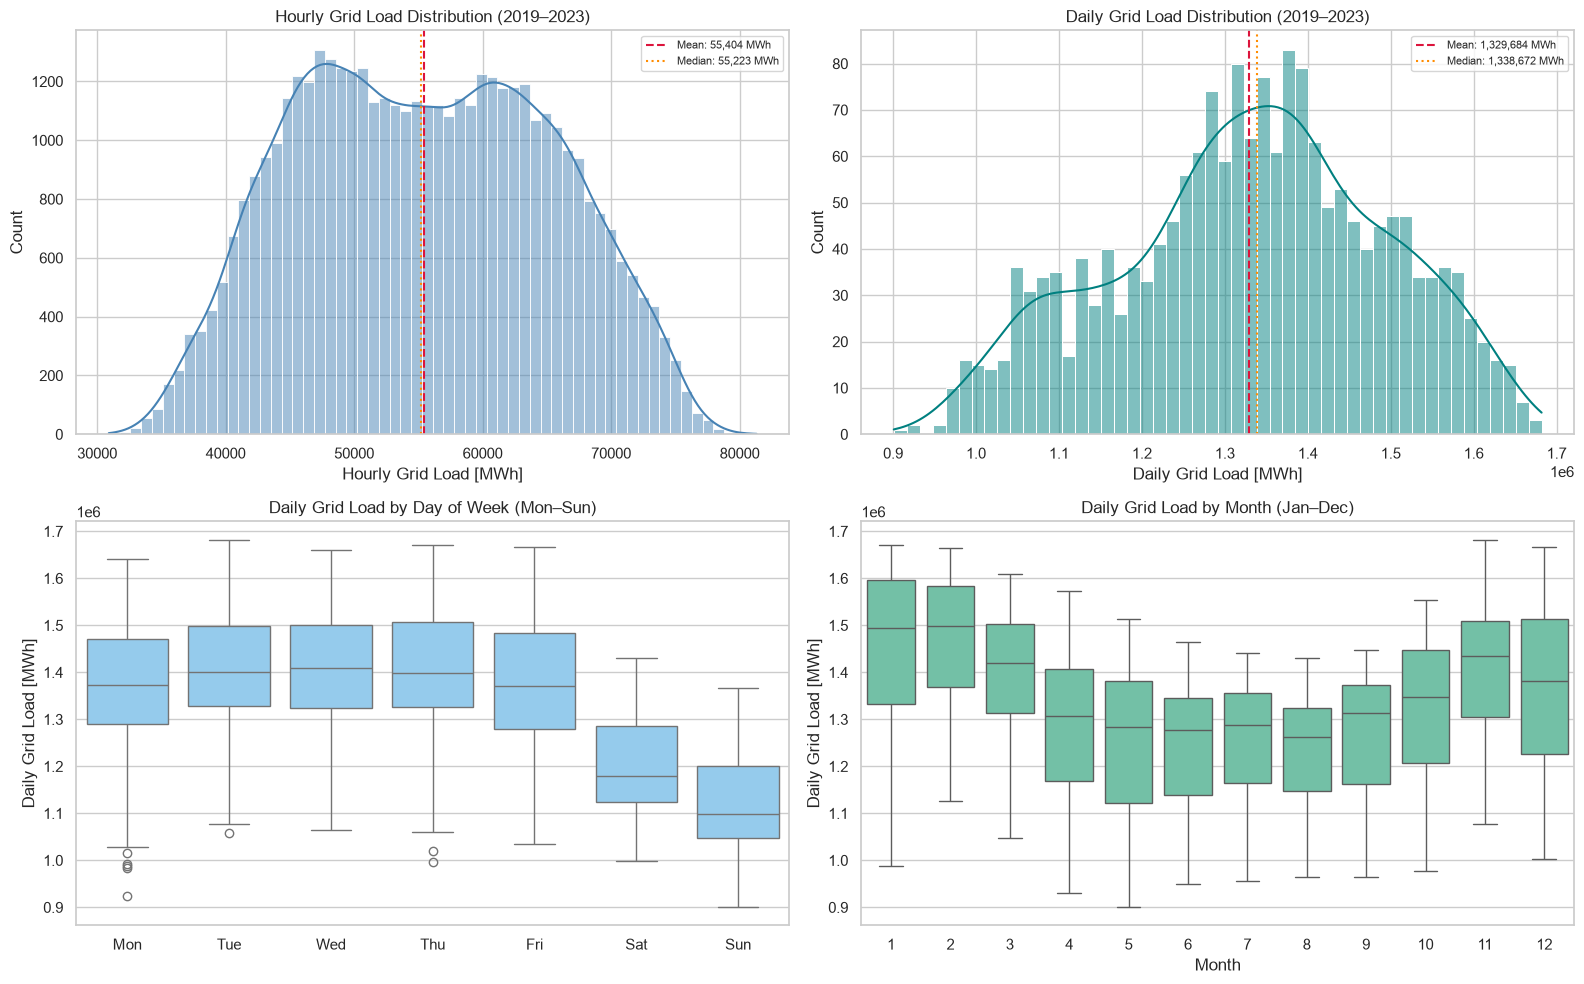

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Hourly load distribution
sns.histplot(train_h[TARGET_COL], bins=60, kde=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].axvline(train_h[TARGET_COL].mean(), color="crimson", ls="--", lw=1.5, label=f"Mean: {train_h[TARGET_COL].mean():,.0f} MWh")
axes[0, 0].axvline(train_h[TARGET_COL].median(), color="darkorange", ls=":", lw=1.5, label=f"Median: {train_h[TARGET_COL].median():,.0f} MWh")
axes[0, 0].set_title("Hourly Grid Load Distribution (2019–2023)")
axes[0, 0].set_xlabel("Hourly Grid Load [MWh]")
axes[0, 0].legend(fontsize=8)

# 2. Daily load distribution
sns.histplot(train_d[TARGET_COL], bins=50, kde=True, color="teal", ax=axes[0, 1])
axes[0, 1].axvline(train_d[TARGET_COL].mean(), color="crimson", ls="--", lw=1.5, label=f"Mean: {train_d[TARGET_COL].mean():,.0f} MWh")
axes[0, 1].axvline(train_d[TARGET_COL].median(), color="darkorange", ls=":", lw=1.5, label=f"Median: {train_d[TARGET_COL].median():,.0f} MWh")
axes[0, 1].set_title("Daily Grid Load Distribution (2019–2023)")
axes[0, 1].set_xlabel("Daily Grid Load [MWh]")
axes[0, 1].legend(fontsize=8)

# 3. Daily load by day of week
sns.boxplot(data=train_d, x="day_of_week", y=TARGET_COL, ax=axes[1, 0], color="lightskyblue")
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(DOW_NAMES)
axes[1, 0].set_title("Daily Grid Load by Day of Week (Mon–Sun)")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Daily Grid Load [MWh]")

# 4. Daily load by month
sns.boxplot(data=train_d, x="month", y=TARGET_COL, ax=axes[1, 1], color="mediumaquamarine")
axes[1, 1].set_title("Daily Grid Load by Month (Jan–Dec)")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Daily Grid Load [MWh]")

plt.tight_layout()
plt.show()


## 2. Weather Covariates & Temperature Sensitivity (2019–2023)


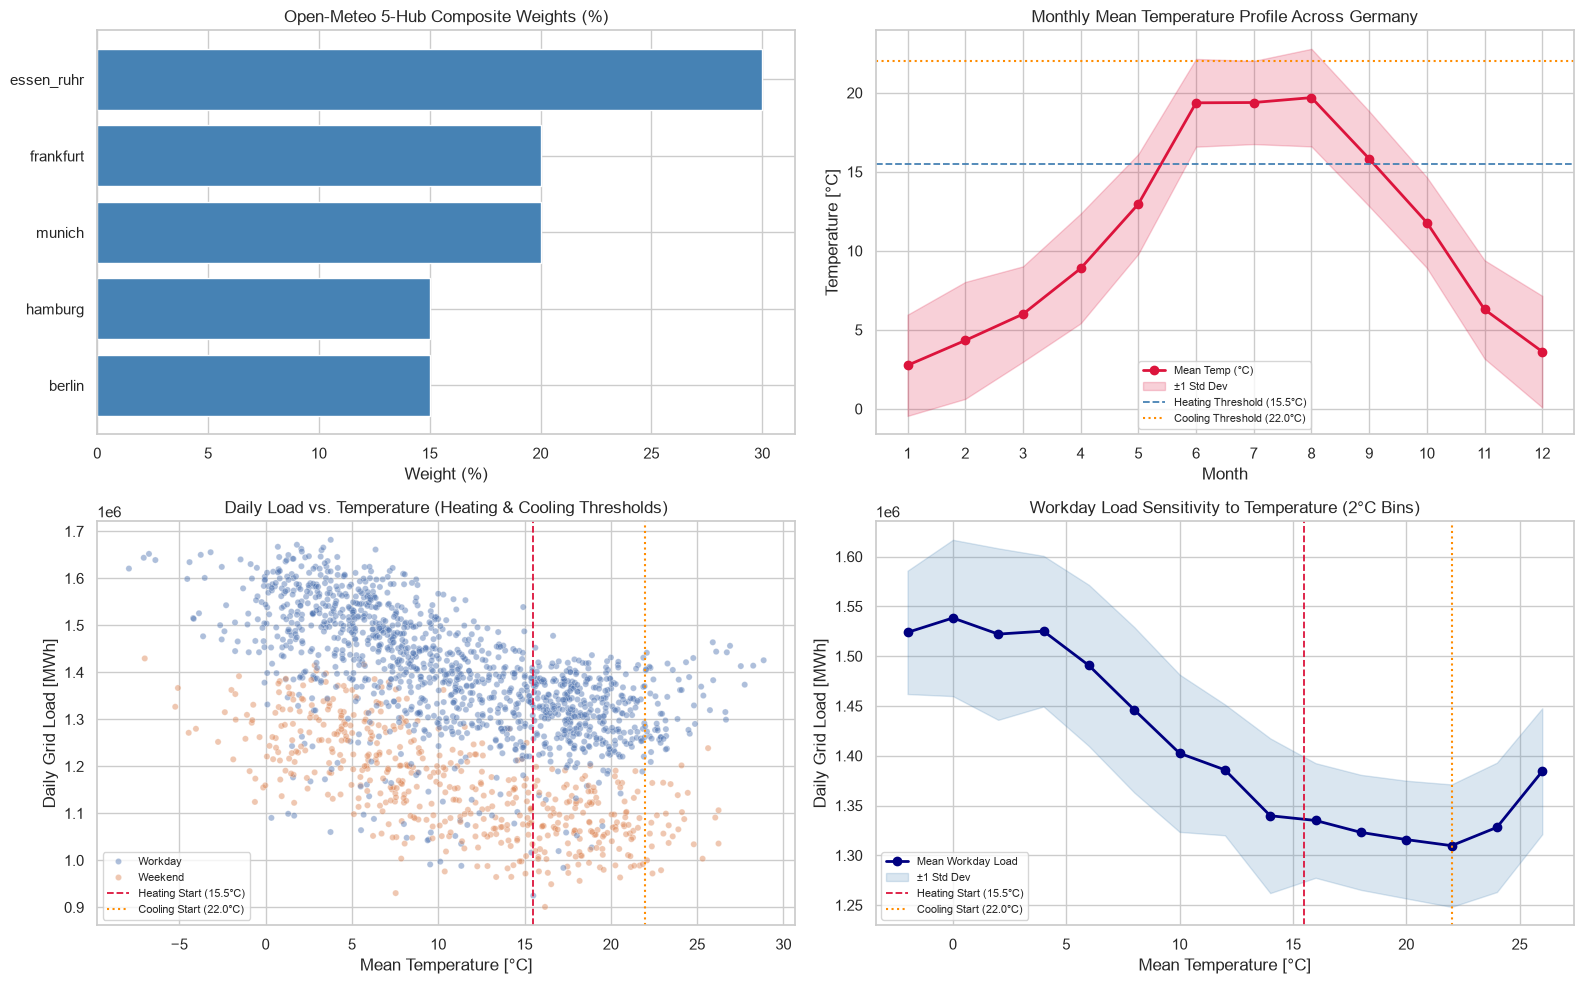

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Hub weights
hub_df = pd.DataFrame(GERMAN_WEATHER_HUBS).sort_values("weight", ascending=True)
axes[0, 0].barh(hub_df["name"], hub_df["weight"] * 100, color="steelblue")
axes[0, 0].set_title("Open-Meteo 5-Hub Composite Weights (%)")
axes[0, 0].set_xlabel("Weight (%)")

# 2. Monthly Temperature Mean ± Std Dev with Heating (15.5°C) & Cooling (22.0°C) thresholds
monthly_temp = train_d.groupby("month")["temp_c_mean"].agg(["mean", "std"])
axes[0, 1].plot(monthly_temp.index, monthly_temp["mean"], marker="o", lw=2, color="crimson", label="Mean Temp (°C)")
axes[0, 1].fill_between(
    monthly_temp.index,
    monthly_temp["mean"] - monthly_temp["std"],
    monthly_temp["mean"] + monthly_temp["std"],
    alpha=0.2,
    color="crimson",
    label="±1 Std Dev",
)
axes[0, 1].axhline(15.5, color="steelblue", ls="--", lw=1.3, label="Heating Threshold (15.5°C)")
axes[0, 1].axhline(22.0, color="darkorange", ls=":", lw=1.5, label="Cooling Threshold (22.0°C)")
axes[0, 1].set_title("Monthly Mean Temperature Profile Across Germany")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Temperature [°C]")
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].legend(fontsize=8)

# 3. Daily Load vs Mean Temperature (with both 15.5°C and 22°C lines)
sns.scatterplot(
    data=train_d.assign(day_type=train_d["is_weekend"].map({0: "Workday", 1: "Weekend"})),
    x="temp_c_mean",
    y=TARGET_COL,
    hue="day_type",
    alpha=0.45,
    s=20,
    ax=axes[1, 0],
)
axes[1, 0].axvline(15.5, color="crimson", ls="--", lw=1.3, label="Heating Start (15.5°C)")
axes[1, 0].axvline(22.0, color="darkorange", ls=":", lw=1.5, label="Cooling Start (22.0°C)")
axes[1, 0].set_title("Daily Load vs. Temperature (Heating & Cooling Thresholds)")
axes[1, 0].set_xlabel("Mean Temperature [°C]")
axes[1, 0].set_ylabel("Daily Grid Load [MWh]")
axes[1, 0].legend(fontsize=8)

# 4. Binned Temperature Response Curve (2°C bins, Regular Workdays)
wd = train_d.loc[train_d["day_category"] == "Regular Workday"].copy()
wd["temp_bin"] = (wd["temp_c_mean"] / 2.0).round() * 2.0
temp_curve = wd.groupby("temp_bin")[TARGET_COL].agg(["mean", "std", "count"]).query("count >= 10")
axes[1, 1].plot(temp_curve.index, temp_curve["mean"], marker="o", color="navy", lw=2, label="Mean Workday Load")
axes[1, 1].fill_between(temp_curve.index, temp_curve["mean"] - temp_curve["std"], temp_curve["mean"] + temp_curve["std"], alpha=0.2, color="steelblue", label="±1 Std Dev")
axes[1, 1].axvline(15.5, color="crimson", ls="--", lw=1.3, label="Heating Start (15.5°C)")
axes[1, 1].axvline(22.0, color="darkorange", ls=":", lw=1.5, label="Cooling Start (22.0°C)")
axes[1, 1].set_title("Workday Load Sensitivity to Temperature (2°C Bins)")
axes[1, 1].set_xlabel("Mean Temperature [°C]")
axes[1, 1].set_ylabel("Daily Grid Load [MWh]")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()


## 3. Seasonal Distributions, Diurnal Curves & Weather Heatmaps (2019–2023)


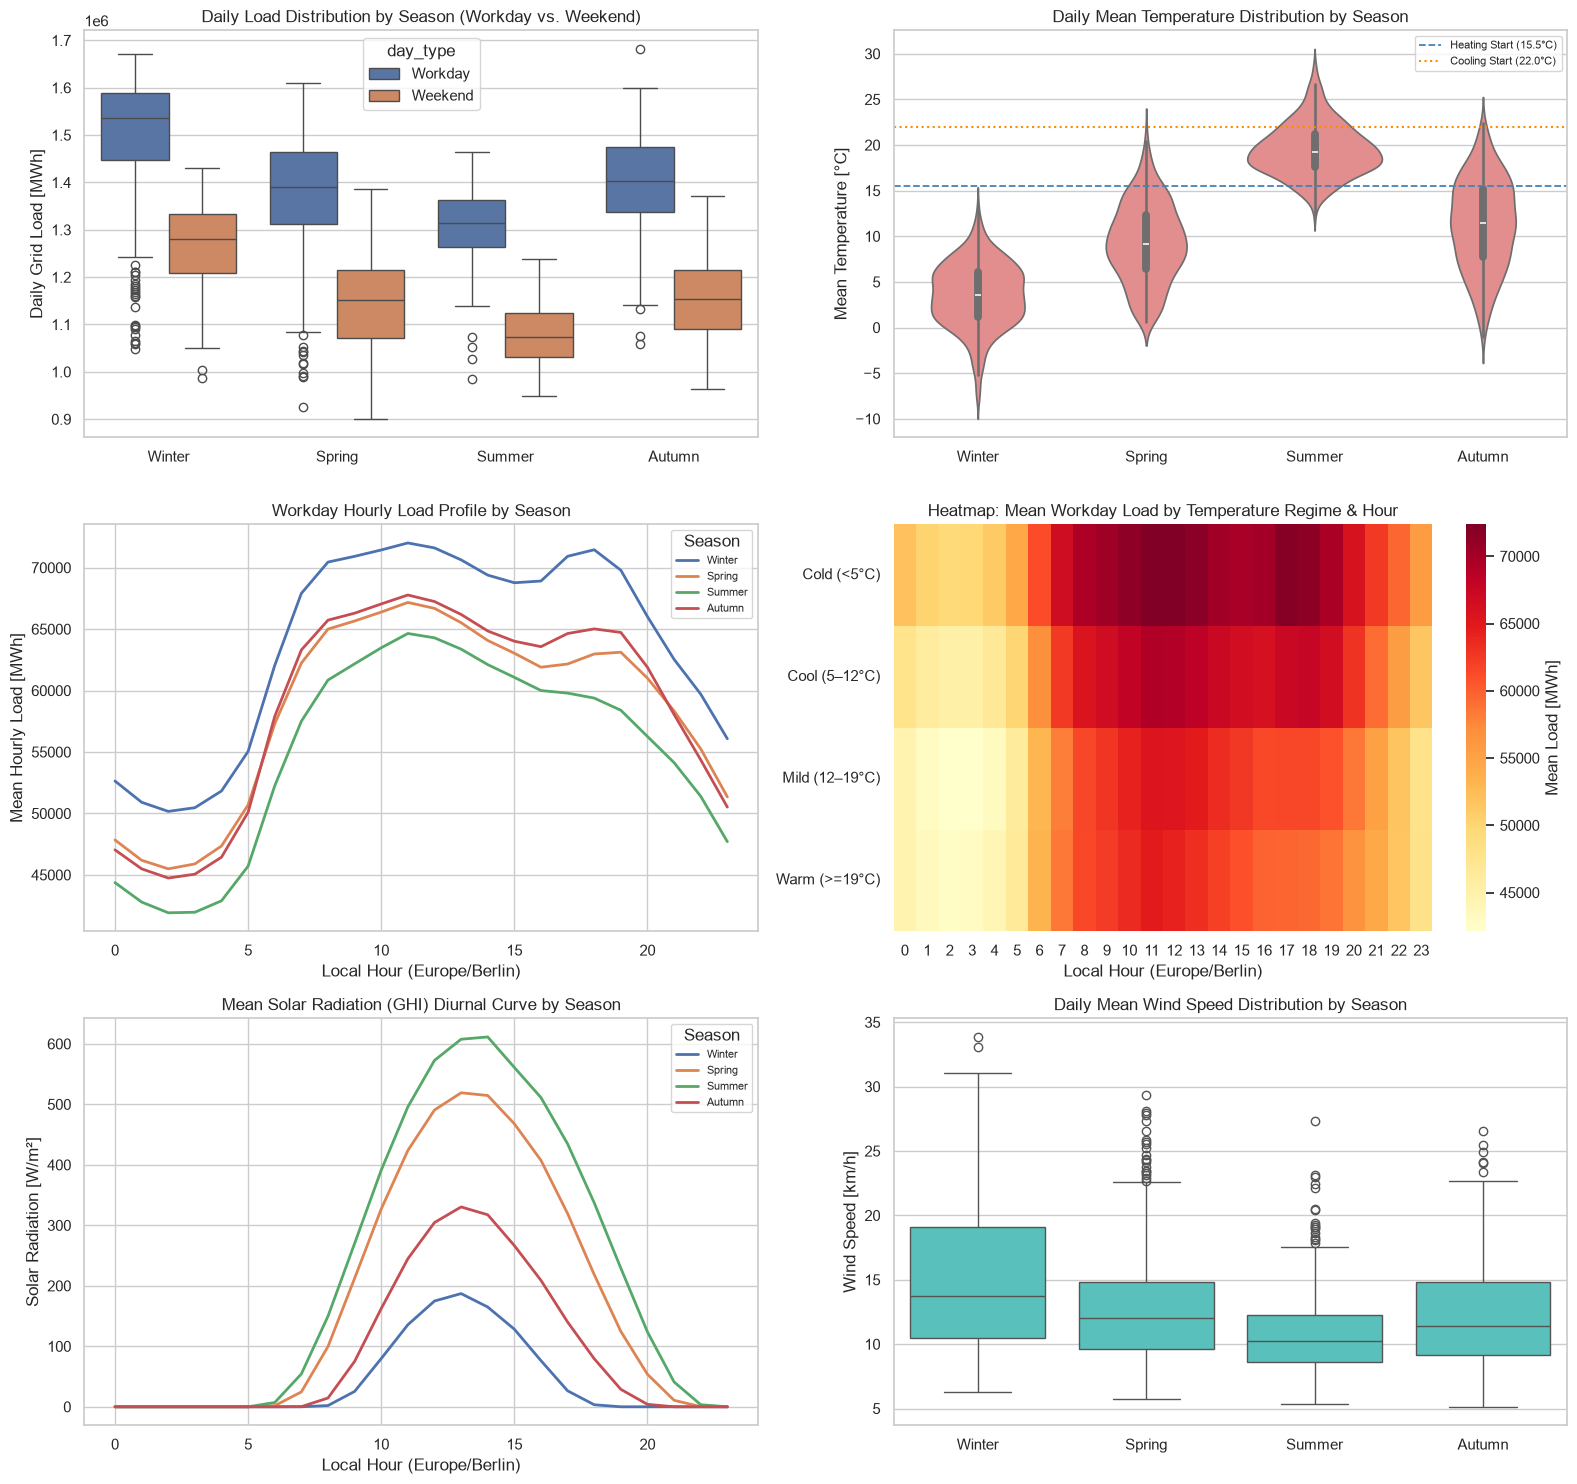

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

# 1. Seasonal Daily Load Distribution (Workday vs Weekend)
sns.boxplot(
    data=train_d.assign(day_type=train_d["is_weekend"].map({0: "Workday", 1: "Weekend"})),
    x="season",
    y=TARGET_COL,
    hue="day_type",
    order=SEASON_ORDER,
    ax=axes[0, 0],
)
axes[0, 0].set_title("Daily Load Distribution by Season (Workday vs. Weekend)")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Daily Grid Load [MWh]")

# 2. Restored: Seasonal Temperature Distribution (Violin Plot)
sns.violinplot(data=train_d, x="season", y="temp_c_mean", order=SEASON_ORDER, color="lightcoral", ax=axes[0, 1])
axes[0, 1].axhline(15.5, color="steelblue", ls="--", lw=1.3, label="Heating Start (15.5°C)")
axes[0, 1].axhline(22.0, color="darkorange", ls=":", lw=1.5, label="Cooling Start (22.0°C)")
axes[0, 1].set_title("Daily Mean Temperature Distribution by Season")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Mean Temperature [°C]")
axes[0, 1].legend(fontsize=8)

# 3. Seasonal Workday Diurnal Load Curve
wd_h = train_h.loc[train_h["day_category"] == "Regular Workday"].copy()
wd_h.groupby(["hour", "season"])[TARGET_COL].mean().unstack()[SEASON_ORDER].plot(ax=axes[1, 0], lw=2)
axes[1, 0].set_title("Workday Hourly Load Profile by Season")
axes[1, 0].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 0].set_ylabel("Mean Hourly Load [MWh]")
axes[1, 0].legend(title="Season", fontsize=8)

# 4. Workday Hourly Profile by Temperature Regime + Zero-NaN Heatmap
wd_h["temp_regime"] = pd.cut(
    wd_h["temp_c"],
    bins=[-30, 5, 12, 19, 45],
    labels=["Cold (<5°C)", "Cool (5–12°C)", "Mild (12–19°C)", "Warm (>=19°C)"],
)
hm_temp = wd_h.pivot_table(index="temp_regime", columns="hour", values=TARGET_COL, aggfunc="mean", observed=False)
assert not hm_temp.isna().any().any(), "Unexpected NaNs in temperature heatmap!"
sns.heatmap(hm_temp, cmap="YlOrRd", ax=axes[1, 1], cbar_kws={"label": "Mean Load [MWh]"})
axes[1, 1].set_title("Heatmap: Mean Workday Load by Temperature Regime & Hour")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("")

# 5. Solar Radiation Diurnal Curve by Season
train_h.groupby(["hour", "season"])["solar_radiation_wm2"].mean().unstack()[SEASON_ORDER].plot(ax=axes[2, 0], lw=2)
axes[2, 0].set_title("Mean Solar Radiation (GHI) Diurnal Curve by Season")
axes[2, 0].set_xlabel("Local Hour (Europe/Berlin)")
axes[2, 0].set_ylabel("Solar Radiation [W/m²]")
axes[2, 0].legend(title="Season", fontsize=8)

# 6. Wind Speed Distribution by Season
sns.boxplot(data=train_d, x="season", y="wind_speed_kmh_mean", order=SEASON_ORDER, color="mediumturquoise", ax=axes[2, 1])
axes[2, 1].set_title("Daily Mean Wind Speed Distribution by Season")
axes[2, 1].set_xlabel("")
axes[2, 1].set_ylabel("Wind Speed [km/h]")

plt.tight_layout()
plt.show()


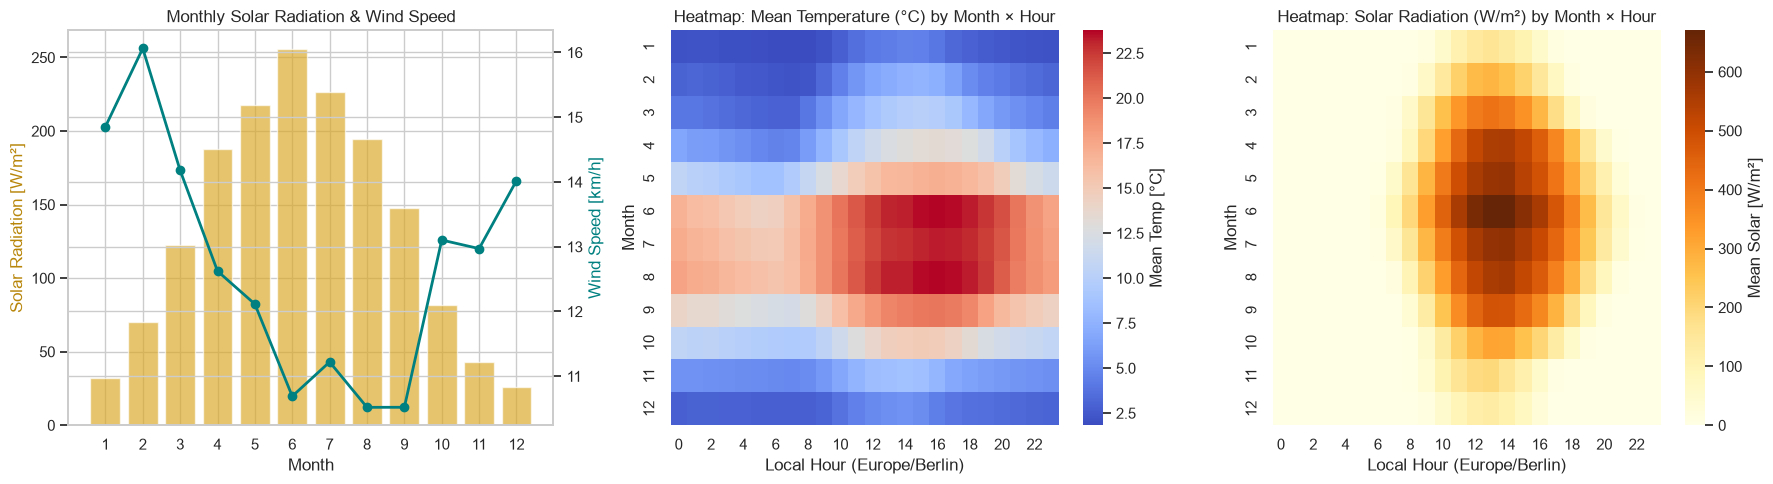

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Monthly Solar Radiation & Wind Speed dual axis
monthly_wx = train_d.groupby("month")[["solar_radiation_wm2_mean", "wind_speed_kmh_mean"]].mean()
ax_t = axes[0].twinx()
axes[0].bar(monthly_wx.index, monthly_wx["solar_radiation_wm2_mean"], alpha=0.65, color="goldenrod")
ax_t.plot(monthly_wx.index, monthly_wx["wind_speed_kmh_mean"], color="teal", marker="o", lw=2)
axes[0].set_title("Monthly Solar Radiation & Wind Speed")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Solar Radiation [W/m²]", color="darkgoldenrod")
ax_t.set_ylabel("Wind Speed [km/h]", color="teal")
axes[0].set_xticks(range(1, 13))

# 2. Heatmap: Temperature by Month x Hour
hm_wx_t = train_h.pivot_table(index="month", columns="hour", values="temp_c", aggfunc="mean")
assert not hm_wx_t.isna().any().any()
sns.heatmap(hm_wx_t, cmap="coolwarm", ax=axes[1], cbar_kws={"label": "Mean Temp [°C]"})
axes[1].set_title("Heatmap: Mean Temperature (°C) by Month × Hour")
axes[1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1].set_ylabel("Month")

# 3. Heatmap: Solar Radiation by Month x Hour
hm_wx_s = train_h.pivot_table(index="month", columns="hour", values="solar_radiation_wm2", aggfunc="mean")
assert not hm_wx_s.isna().any().any()
sns.heatmap(hm_wx_s, cmap="YlOrBr", ax=axes[2], cbar_kws={"label": "Mean Solar [W/m²]"})
axes[2].set_title("Heatmap: Solar Radiation (W/m²) by Month × Hour")
axes[2].set_xlabel("Local Hour (Europe/Berlin)")
axes[2].set_ylabel("Month")

plt.tight_layout()
plt.show()


## 4. German Holidays, `holiday_weight`, Bridge Days & Calendar Categories (2019–2023)


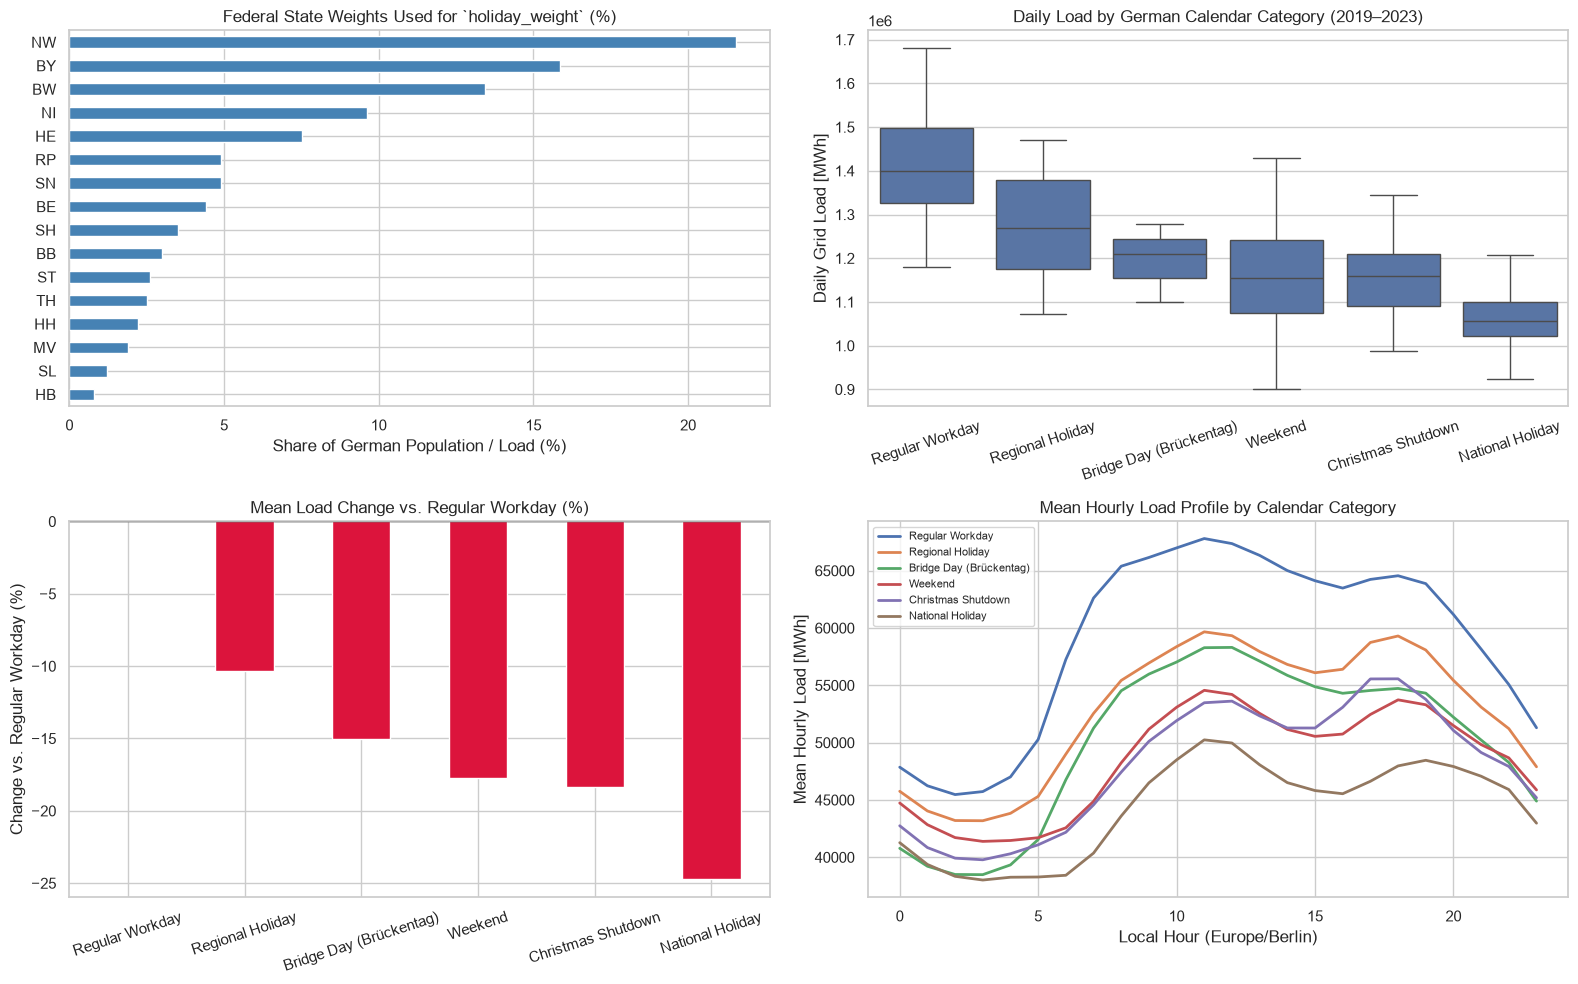

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Federal state weights used in holiday_weight
sw = pd.Series(STATE_WEIGHTS).sort_values(ascending=True) * 100
sw.plot(kind="barh", color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Federal State Weights Used for `holiday_weight` (%)")
axes[0, 0].set_xlabel("Share of German Population / Load (%)")

# 2. Daily load boxplot by German calendar category (sorted per requested order)
sns.boxplot(data=train_d, x="day_category", y=TARGET_COL, order=CAT_ORDER, ax=axes[0, 1])
axes[0, 1].set_title("Daily Load by German Calendar Category (2019–2023)")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Daily Grid Load [MWh]")
axes[0, 1].tick_params(axis="x", rotation=18)

# 3. Percentage load drop relative to Regular Workday (sorted per requested order)
cat_means = train_d.groupby("day_category")[TARGET_COL].mean().reindex(CAT_ORDER)
pct_diff = ((cat_means / cat_means["Regular Workday"]) - 1.0) * 100.0
colors = ["steelblue" if v >= 0 else "crimson" for v in pct_diff]
pct_diff.plot(kind="bar", color=colors, ax=axes[1, 0])
axes[1, 0].axhline(0, color="black", lw=1)
axes[1, 0].set_title("Mean Load Change vs. Regular Workday (%)")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Change vs. Regular Workday (%)")
axes[1, 0].tick_params(axis="x", rotation=18)

# 4. Hourly Diurnal Curves by German Calendar Category
cat_diurnal = train_h.pivot_table(index="hour", columns="day_category", values=TARGET_COL, aggfunc="mean")[CAT_ORDER]
cat_diurnal.plot(ax=axes[1, 1], lw=2)
axes[1, 1].set_title("Mean Hourly Load Profile by Calendar Category")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("Mean Hourly Load [MWh]")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()


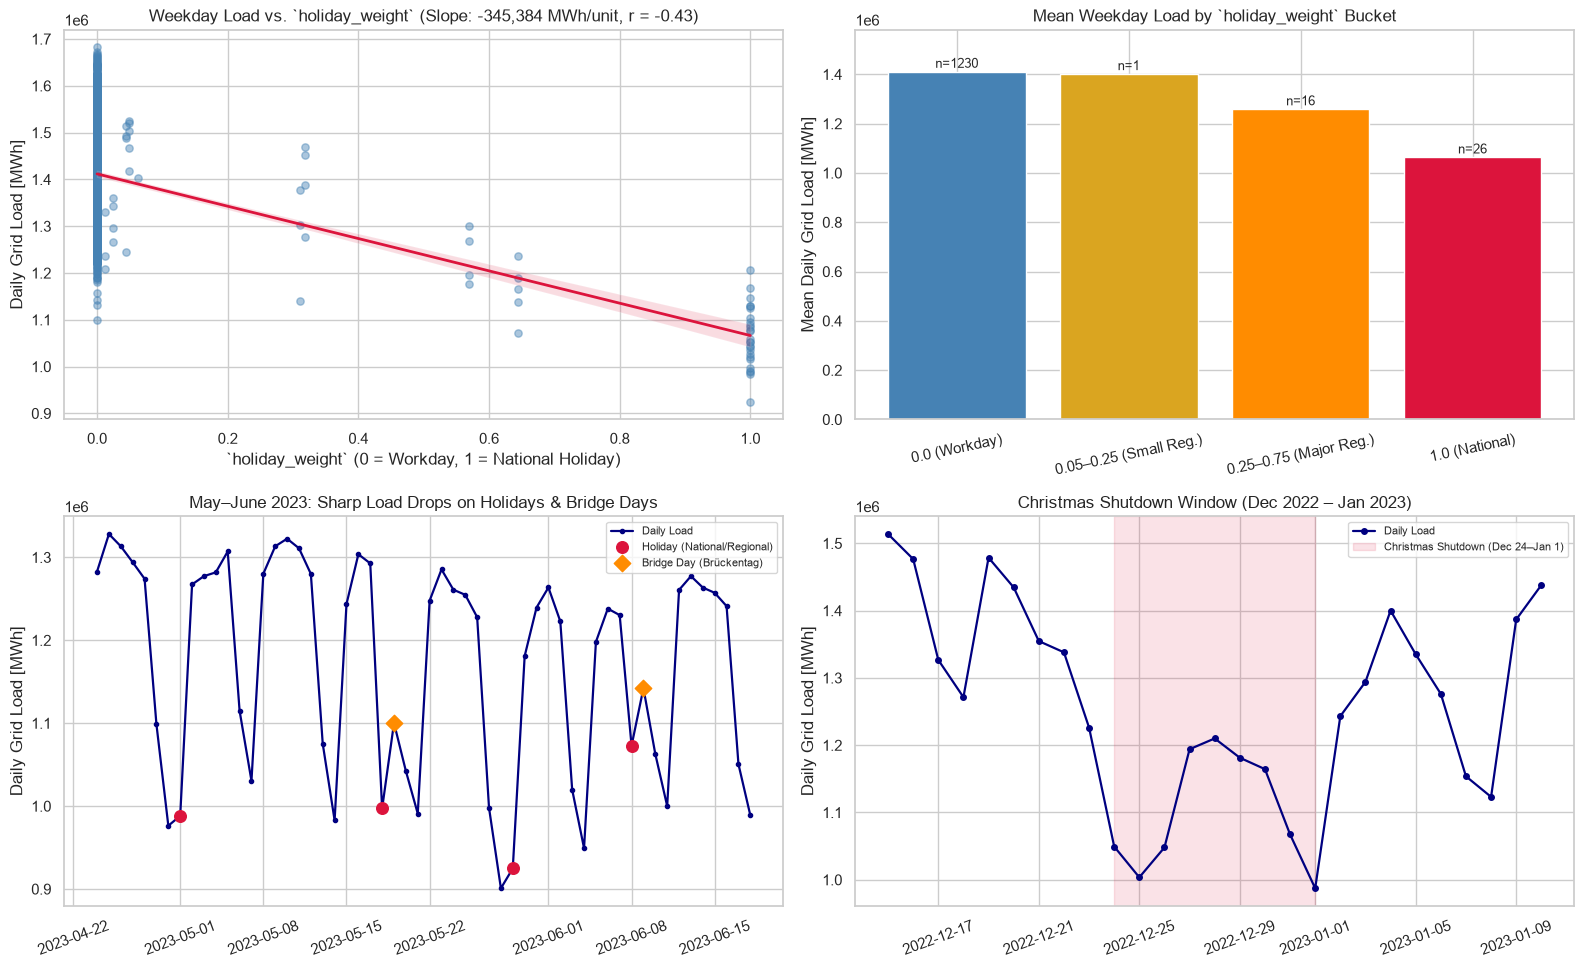

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Scatter + OLS regression: holiday_weight vs Daily Load on Weekdays (excl. Christmas shutdown)
wkdays = train_d.loc[(train_d["is_weekend"] == 0) & (train_d["is_christmas_shutdown"] == 0)].copy()
sns.regplot(
    data=wkdays,
    x="holiday_weight",
    y=TARGET_COL,
    scatter_kws={"alpha": 0.45, "s": 28, "color": "steelblue"},
    line_kws={"color": "crimson", "lw": 2},
    ax=axes[0, 0],
)
slope = np.polyfit(wkdays["holiday_weight"], wkdays[TARGET_COL], 1)[0]
corr_hw = wkdays["holiday_weight"].corr(wkdays[TARGET_COL])
axes[0, 0].set_title(f"Weekday Load vs. `holiday_weight` (Slope: {slope:,.0f} MWh/unit, r = {corr_hw:.2f})")
axes[0, 0].set_xlabel("`holiday_weight` (0 = Workday, 1 = National Holiday)")
axes[0, 0].set_ylabel("Daily Grid Load [MWh]")

# 2. Mean Weekday Load by holiday_weight Bucket with counts
wkdays["hw_bucket"] = pd.cut(
    wkdays["holiday_weight"],
    bins=[-0.01, 0.05, 0.25, 0.75, 1.01],
    labels=["0.0 (Workday)", "0.05–0.25 (Small Reg.)", "0.25–0.75 (Major Reg.)", "1.0 (National)"],
)
bucket_stats = wkdays.groupby("hw_bucket", observed=False)[TARGET_COL].agg(["mean", "count"])
bars = axes[0, 1].bar(bucket_stats.index.astype(str), bucket_stats["mean"], color=["steelblue", "goldenrod", "darkorange", "crimson"])
for bar, (_, row) in zip(bars, bucket_stats.iterrows()):
    axes[0, 1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 15000, f"n={int(row['count'])}", ha="center", fontsize=9)
axes[0, 1].set_ylim(0, bucket_stats["mean"].max() * 1.12)
axes[0, 1].set_title("Mean Weekday Load by `holiday_weight` Bucket")
axes[0, 1].set_ylabel("Mean Daily Grid Load [MWh]")
axes[0, 1].tick_params(axis="x", rotation=12)

# 3. Zoomed-In May–June 2023 holiday window
spring23 = train_d.loc[(train_d["date_local"] >= "2023-04-24") & (train_d["date_local"] <= "2023-06-18")].copy()
axes[1, 0].plot(spring23["date_local"], spring23[TARGET_COL], color="navy", lw=1.6, marker="o", ms=3, label="Daily Load")
hol_pts = spring23.loc[spring23["holiday_weight"] > 0.05]
br_pts = spring23.loc[spring23["is_bridge_day"] == 1]
axes[1, 0].scatter(hol_pts["date_local"], hol_pts[TARGET_COL], color="crimson", s=70, zorder=5, label="Holiday (National/Regional)")
axes[1, 0].scatter(br_pts["date_local"], br_pts[TARGET_COL], color="darkorange", s=70, marker="D", zorder=5, label="Bridge Day (Brückentag)")
axes[1, 0].set_title("May–June 2023: Sharp Load Drops on Holidays & Bridge Days")
axes[1, 0].set_ylabel("Daily Grid Load [MWh]")
axes[1, 0].tick_params(axis="x", rotation=20)
axes[1, 0].legend(fontsize=8)

# 4. Zoomed-In Christmas Shutdown Window (Dec 2022 – Jan 2023)
xmas = train_d.loc[(train_d["date_local"] >= "2022-12-15") & (train_d["date_local"] <= "2023-01-10")].copy()
axes[1, 1].plot(xmas["date_local"], xmas[TARGET_COL], color="navy", lw=1.6, marker="o", ms=4, label="Daily Load")
xmas_pts = xmas.loc[xmas["is_christmas_shutdown"] == 1]
axes[1, 1].axvspan(xmas_pts["date_local"].min(), xmas_pts["date_local"].max(), color="crimson", alpha=0.12, label="Christmas Shutdown (Dec 24–Jan 1)")
axes[1, 1].set_title("Christmas Shutdown Window (Dec 2022 – Jan 2023)")
axes[1, 1].set_ylabel("Daily Grid Load [MWh]")
axes[1, 1].tick_params(axis="x", rotation=20)
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()


## 5. Calendar Heatmaps: Weekly, Seasonal & Holiday-Type Rhythms


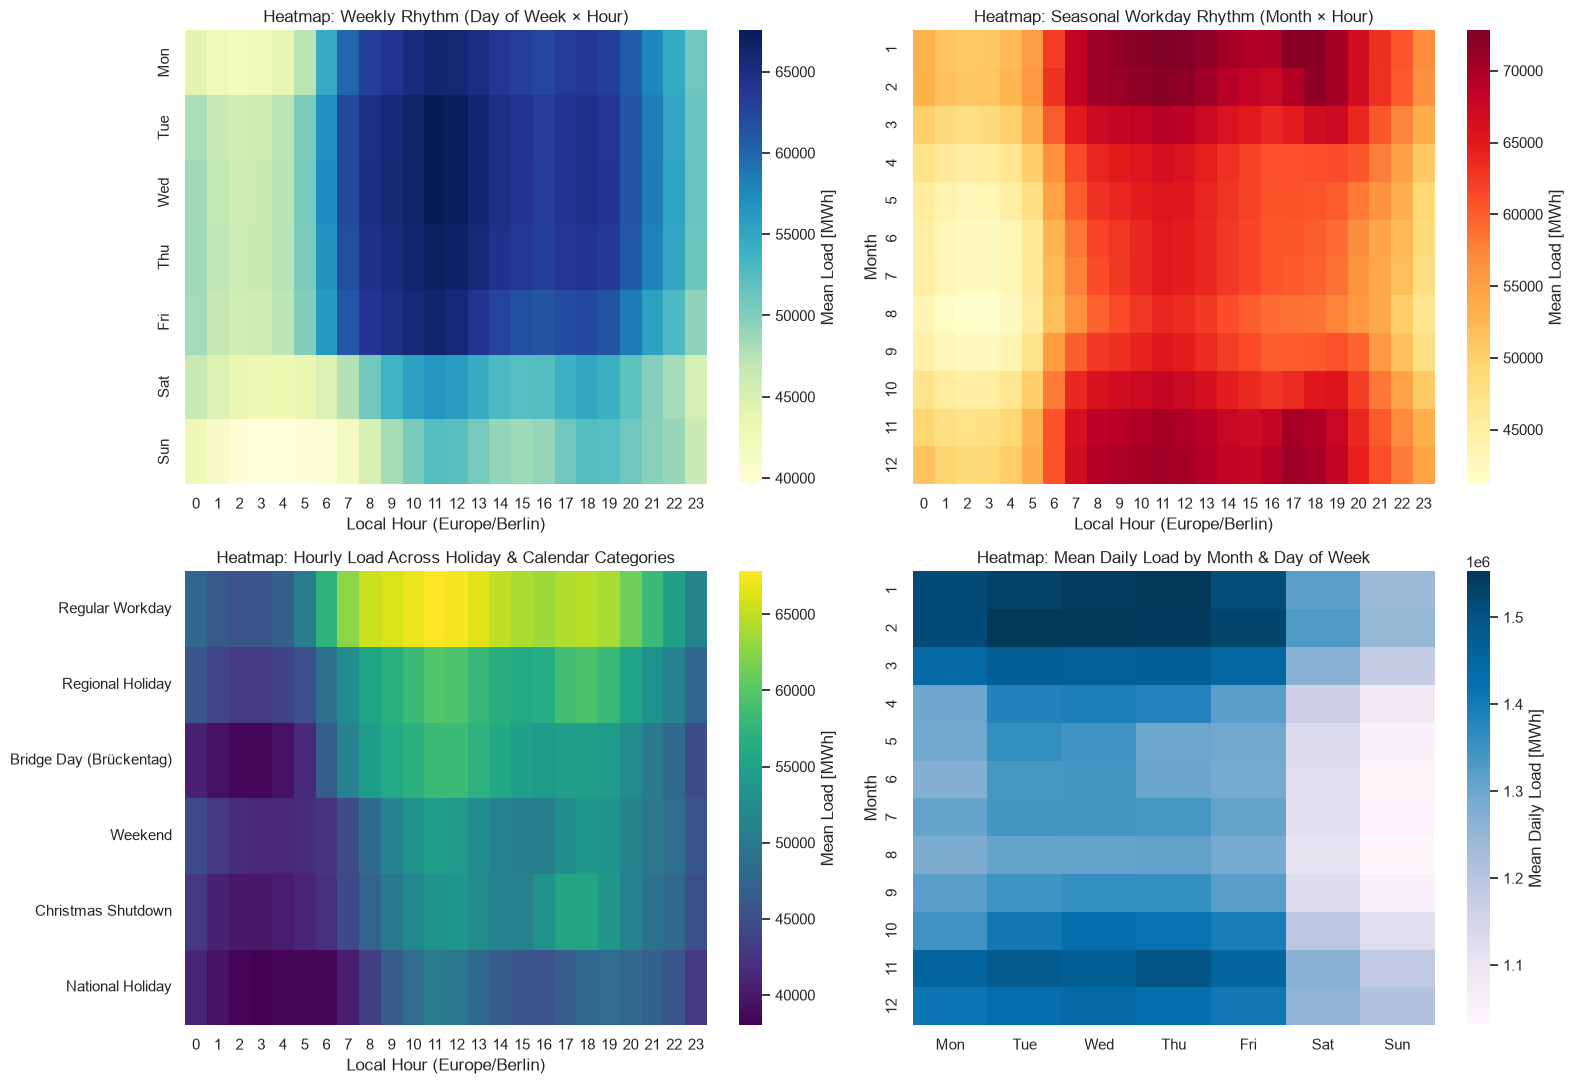

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Heatmap: Day of Week x Hour of Day
hm_week = train_h.pivot_table(index="day_of_week", columns="hour", values=TARGET_COL, aggfunc="mean")
hm_week.index = [DOW_NAMES[i] for i in hm_week.index]
assert not hm_week.isna().any().any()
sns.heatmap(hm_week, cmap="YlGnBu", ax=axes[0, 0], cbar_kws={"label": "Mean Load [MWh]"})
axes[0, 0].set_title("Heatmap: Weekly Rhythm (Day of Week × Hour)")
axes[0, 0].set_xlabel("Local Hour (Europe/Berlin)")
axes[0, 0].set_ylabel("")

# 2. Heatmap: Month x Hour of Day (Regular Workdays)
hm_month = wd_h.pivot_table(index="month", columns="hour", values=TARGET_COL, aggfunc="mean")
assert not hm_month.isna().any().any()
sns.heatmap(hm_month, cmap="YlOrRd", ax=axes[0, 1], cbar_kws={"label": "Mean Load [MWh]"})
axes[0, 1].set_title("Heatmap: Seasonal Workday Rhythm (Month × Hour)")
axes[0, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[0, 1].set_ylabel("Month")

# 3. Heatmap: Day Category x Hour of Day (sorted per requested order)
hm_cat = train_h.pivot_table(index="day_category", columns="hour", values=TARGET_COL, aggfunc="mean").reindex(CAT_ORDER)
assert not hm_cat.isna().any().any()
sns.heatmap(hm_cat, cmap="viridis", ax=axes[1, 0], cbar_kws={"label": "Mean Load [MWh]"})
axes[1, 0].set_title("Heatmap: Hourly Load Across Holiday & Calendar Categories")
axes[1, 0].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 0].set_ylabel("")

# 4. Heatmap: Month x Day of Week (Daily Load)
hm_dow_m = train_d.pivot_table(index="month", columns="day_of_week", values=TARGET_COL, aggfunc="mean")
hm_dow_m.columns = DOW_NAMES
assert not hm_dow_m.isna().any().any()
sns.heatmap(hm_dow_m, cmap="PuBu", ax=axes[1, 1], cbar_kws={"label": "Mean Daily Load [MWh]"})
axes[1, 1].set_title("Heatmap: Mean Daily Load by Month & Day of Week")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Month")

plt.tight_layout()
plt.show()


## 6. Multi-Year Global Trend & Detrending Analysis (2019–2023)


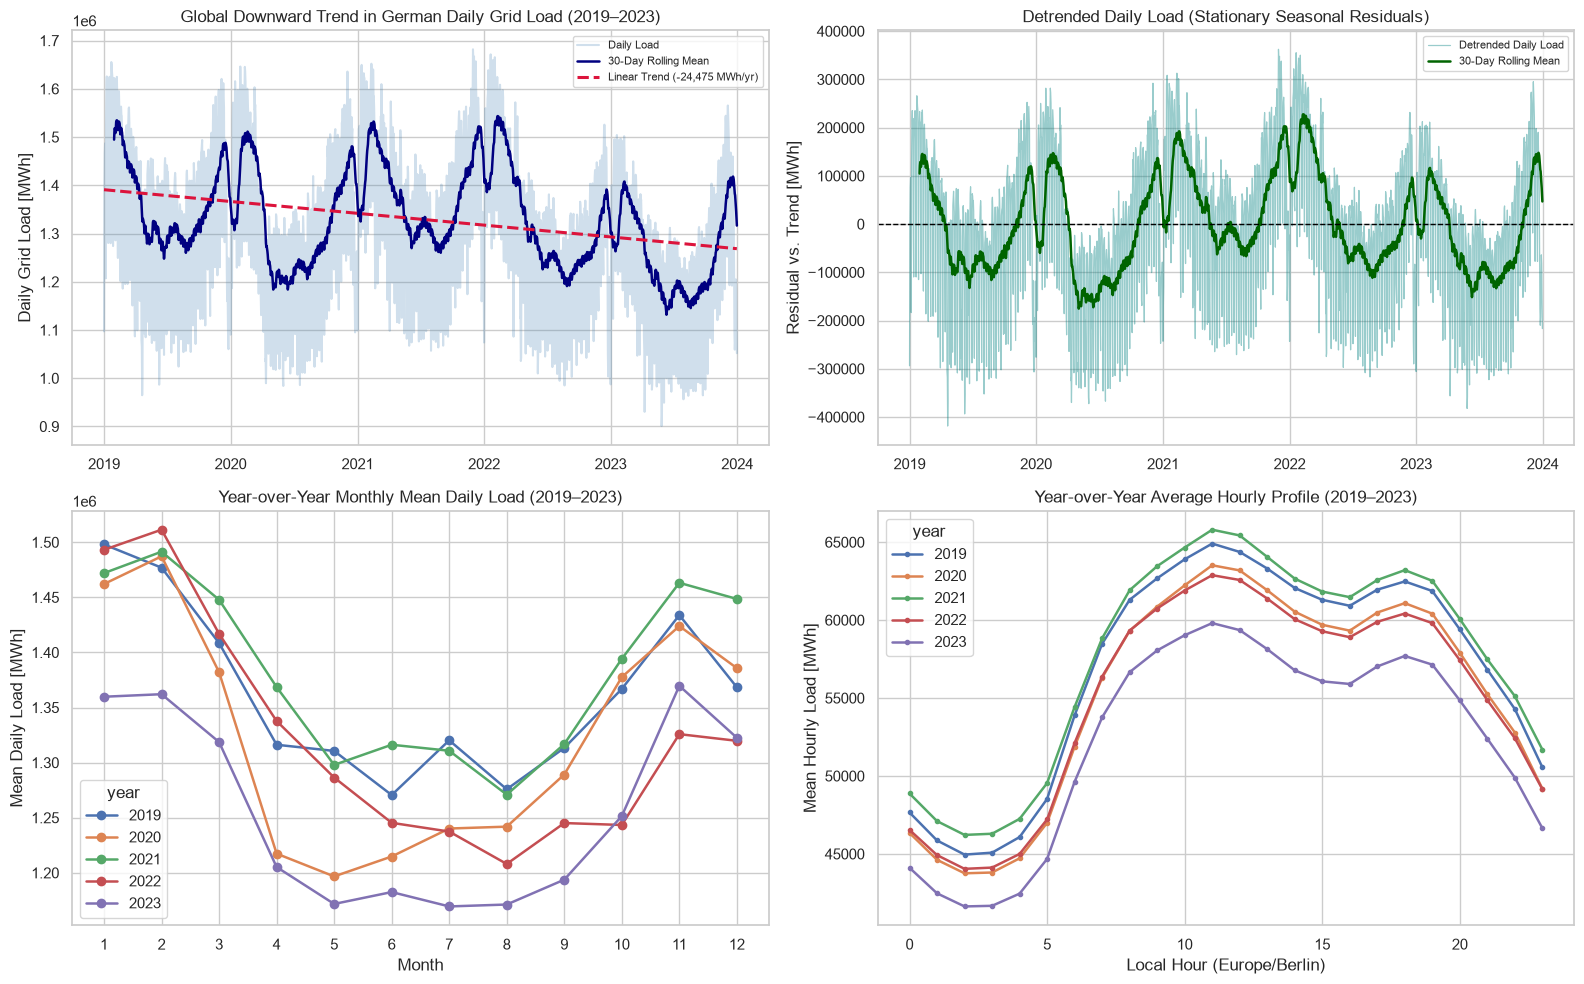

In [9]:
trend_reg = LinearRegression().fit(train_d[["time_years"]], train_d[TARGET_COL])
train_d["trend"] = trend_reg.predict(train_d[["time_years"]])
train_d["detrended"] = train_d[TARGET_COL] - train_d["trend"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Daily load, 30d rolling mean, and linear global trend
axes[0, 0].plot(train_d["date_local"], train_d[TARGET_COL], alpha=0.25, color="steelblue", label="Daily Load")
axes[0, 0].plot(train_d["date_local"], train_d[TARGET_COL].rolling(30).mean(), color="navy", lw=1.8, label="30-Day Rolling Mean")
axes[0, 0].plot(train_d["date_local"], train_d["trend"], color="crimson", lw=2.2, ls="--", label=f"Linear Trend ({trend_reg.coef_[0]:,.0f} MWh/yr)")
axes[0, 0].set_title("Global Downward Trend in German Daily Grid Load (2019–2023)")
axes[0, 0].set_ylabel("Daily Grid Load [MWh]")
axes[0, 0].legend(fontsize=8)

# 2. Detrended daily residuals
axes[0, 1].plot(train_d["date_local"], train_d["detrended"], alpha=0.4, color="teal", lw=0.9, label="Detrended Daily Load")
axes[0, 1].plot(train_d["date_local"], train_d["detrended"].rolling(30).mean(), color="darkgreen", lw=1.8, label="30-Day Rolling Mean")
axes[0, 1].axhline(0, color="black", ls="--", lw=1)
axes[0, 1].set_title("Detrended Daily Load (Stationary Seasonal Residuals)")
axes[0, 1].set_ylabel("Residual vs. Trend [MWh]")
axes[0, 1].legend(fontsize=8)

# 3. Year-over-year monthly mean load
train_d.pivot_table(index="month", columns="year", values=TARGET_COL, aggfunc="mean").plot(ax=axes[1, 0], marker="o", lw=1.8)
axes[1, 0].set_title("Year-over-Year Monthly Mean Daily Load (2019–2023)")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Mean Daily Load [MWh]")
axes[1, 0].set_xticks(range(1, 13))

# 4. Year-over-year hourly diurnal curve
train_h.pivot_table(index="hour", columns="year", values=TARGET_COL, aggfunc="mean").plot(ax=axes[1, 1], marker="o", ms=3, lw=1.8)
axes[1, 1].set_title("Year-over-Year Average Hourly Profile (2019–2023)")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("Mean Hourly Load [MWh]")

plt.tight_layout()
plt.show()


## 7. Full Feature Correlation Matrices (Daily & Hourly, 2019–2023)


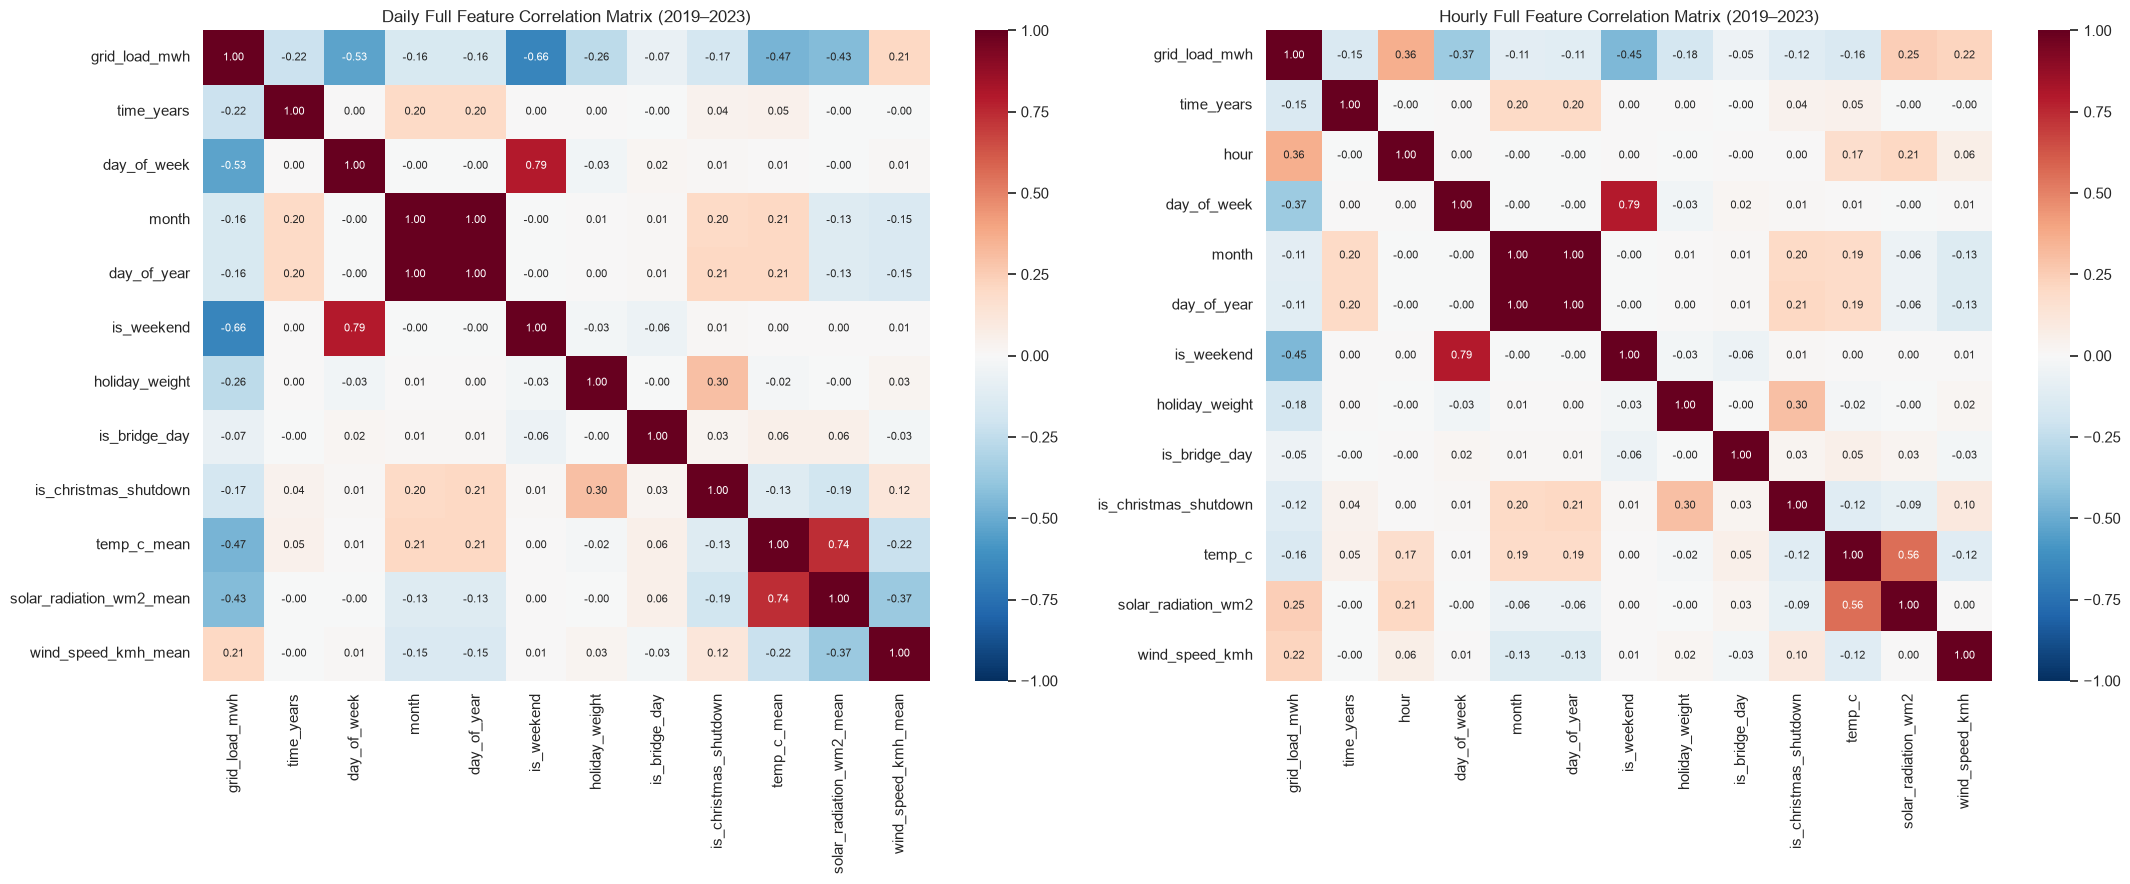

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

daily_corr_cols = [TARGET_COL, *DAILY_FULL_YEAR_COLS]
sns.heatmap(
    train_d[daily_corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
    ax=axes[0],
)
axes[0].set_title("Daily Full Feature Correlation Matrix (2019–2023)")

hourly_corr_cols = [TARGET_COL, *HOURLY_FULL_YEAR_COLS]
sns.heatmap(
    train_h[hourly_corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
    ax=axes[1],
)
axes[1].set_title("Hourly Full Feature Correlation Matrix (2019–2023)")

plt.tight_layout()
plt.show()
